# ML vs DL for Early At-Risk Student Prediction (OULAD)

Starter pipeline for a comparative evaluation of classical machine learning
(Logistic Regression, Random Forest, XGBoost) and deep learning (LSTM, GRU)
for early identification of at-risk students, evaluated at multiple
prediction horizons on the **Open University Learning Analytics Dataset (OULAD)**.

**Runtime:** works on a free Colab GPU (`Runtime > Change runtime type > T4 GPU`).
Full run over 5 horizons takes roughly 20-40 minutes.

**Outputs:**
1. A results table (AUC, F1, at-risk recall, training time) per model per horizon
2. The "money figure": AUC vs. prediction week, one line per model
3. A SHAP summary plot for XGBoost (interpretability dimension)


In [1]:
# --- Setup ---------------------------------------------------------------
!pip -q install shap

import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HORIZONS = [4, 8, 12, 16, 20]          # prediction points, in weeks from course start
KEY = ["code_module", "code_presentation", "id_student"]
print("Device:", DEVICE)

Device: cuda


## 1. Download OULAD

Downloads directly from the Open University. If the direct download fails,
search Kaggle for "OULAD", add it to the notebook via **Add data**, and point
`D` at that folder instead — the CSV file names are identical.


In [6]:
# ============================================================
# STEP 1 - Download OULAD from Kaggle
# ============================================================

import os
import kagglehub
import pandas as pd
import numpy as np

# Keys used throughout the notebook
KEY = ["code_module", "code_presentation", "id_student"]

# Download dataset
DATA_DIR = kagglehub.dataset_download(
    "anlgrbz/student-demographics-online-education-dataoulad"
)

print("Dataset location:")
print(DATA_DIR)

print("\nFiles in dataset:")
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'student-demographics-online-education-dataoulad' dataset.
Dataset location:
/kaggle/input/student-demographics-online-education-dataoulad

Files in dataset:
['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


## 2. Labels and base cohort

At-risk = final result `Fail` or `Withdrawn`. Students who unregistered before
the course started are excluded (they never participated, so predicting them
is meaningless). Later, at each horizon we additionally drop students who had
already withdrawn by that week — an early-warning system only scores
*currently enrolled* students, and keeping withdrawn students would leak the label.


In [7]:
info = pd.read_csv(
    os.path.join(path, "studentInfo.csv")
)

reg = pd.read_csv(
    os.path.join(DATA_DIR, "studentRegistration.csv")
)

# Merge registration information
df = info.merge(
    reg,
    on=KEY,
    how="left"
)

# Remove students who withdrew before the course started
df = df[
    ~(
        df["date_unregistration"] < 0
    )
].copy()

# Binary target
# 1 = Fail or Withdrawn
# 0 = Pass or Distinction
df["at_risk"] = (
    df["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)

print("Class balance (1 = at-risk):")
print(
    df["at_risk"]
    .value_counts(normalize=True)
    .round(3)
)

print("\nCounts:")
print(
    df["at_risk"]
    .value_counts()
)

print("\nFinal result distribution:")
print(
    df["final_result"]
    .value_counts()
)

Class balance (1 = at-risk):
at_risk
0    0.514
1    0.486
Name: proportion, dtype: float64

Counts:
at_risk
0    15385
1    14530
Name: count, dtype: int64

Final result distribution:
final_result
Pass           12361
Withdrawn       7480
Fail            7050
Distinction     3024
Name: count, dtype: int64


## 3. Clickstream preparation

We attach the activity type to every click record and bucket days into weeks.
To keep the feature space manageable we keep the 10 most frequent activity
types and pool the rest into `other`.


In [9]:
# ============================================================
# STEP 3 - Clickstream Preparation
# ============================================================

# Load clickstream tables
svle = pd.read_csv(
    os.path.join(DATA_DIR, "studentVle.csv")
)

vle = pd.read_csv(
    os.path.join(DATA_DIR, "vle.csv")
)

# Attach activity type to each click record
svle = svle.merge(
    vle[["id_site", "activity_type"]]
        .drop_duplicates("id_site"),
    on="id_site",
    how="left"
)

# Keep the 10 most frequent activity types
top_types = (
    svle["activity_type"]
    .value_counts()
    .head(10)
    .index
    .tolist()
)

# Pool remaining activities into "other"
svle["atype"] = np.where(
    svle["activity_type"].isin(top_types),
    svle["activity_type"],
    "other"
)

# Final activity channels
TYPES = top_types + ["other"]

# Convert days to weeks
# Pre-course clicks become week 0
svle["week"] = (
    svle["date"] // 7
).clip(lower=0)

print("Activity channels:")
print(TYPES)

print("\nNumber of channels:", len(TYPES))

print("\nPreview:")
print(
    svle[
        [
            "code_module",
            "code_presentation",
            "id_student",
            "date",
            "week",
            "sum_click",
            "atype"
        ]
    ].head()
)

Activity channels:
['forumng', 'oucontent', 'subpage', 'homepage', 'quiz', 'resource', 'url', 'ouwiki', 'oucollaborate', 'externalquiz', 'other']

Number of channels: 11

Preview:
  code_module code_presentation  id_student  date  week  sum_click      atype
0         AAA             2013J       28400   -10     0          4    forumng
1         AAA             2013J       28400   -10     0          1    forumng
2         AAA             2013J       28400   -10     0          1    forumng
3         AAA             2013J       28400   -10     0         11   homepage
4         AAA             2013J       28400   -10     0          1  oucontent


In [14]:
# ============================================================
# Assessment tables
# ============================================================

sassess = pd.read_csv(
    os.path.join(DATA_DIR, "studentAssessment.csv")
)

assess = pd.read_csv(
    os.path.join(DATA_DIR, "assessments.csv")
)

print("studentAssessment shape:", sassess.shape)
print("assessments shape:", assess.shape)

studentAssessment shape: (173912, 5)
assessments shape: (206, 6)


In [15]:
print(sassess.columns.tolist())
print(assess.columns.tolist())

['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']


## 4. Feature engineering (classical models)

For a horizon of `H` weeks, classical models see hand-crafted aggregates of
everything observed strictly before day `H*7`:

* engagement: total clicks, clicks per activity type, active days, days since
  last activity, linear weekly click trend (slope)
* assessments: number submitted, mean score
* demographics: one-hot encoded (run your ablation with/without these)


In [16]:
DEMO_CAT = ["gender", "highest_education", "imd_band", "age_band", "disability"]
DEMO_NUM = ["num_of_prev_attempts", "studied_credits"]

def build_tabular(H, cohort):
    hdays = H * 7
    clicks = svle[svle.date < hdays]

    g = clicks.groupby(KEY)
    feats = g.agg(total_clicks=("sum_click", "sum"),
                  active_days=("date", "nunique"),
                  last_day=("date", "max")).reset_index()
    feats["days_since_last"] = hdays - feats.last_day
    feats = feats.drop(columns="last_day")

    pt = clicks.pivot_table(index=KEY, columns="atype", values="sum_click",
                            aggfunc="sum", fill_value=0)
    pt = pt.add_prefix("clk_").reset_index()
    feats = feats.merge(pt, on=KEY, how="left")

    # vectorised least-squares slope of weekly clicks
    wk = clicks.groupby(KEY + ["week"]).sum_click.sum().reset_index()
    wk["w2"] = wk.week ** 2
    wk["wc"] = wk.week * wk.sum_click
    a = wk.groupby(KEY).agg(n=("week", "size"), sw=("week", "sum"),
                            sc=("sum_click", "sum"), sww=("w2", "sum"),
                            swc=("wc", "sum")).reset_index()
    den = a.n * a.sww - a.sw ** 2
    a["click_slope"] = np.where(den > 0, (a.n * a.swc - a.sw * a.sc) / den, 0.0)
    feats = feats.merge(a[KEY + ["click_slope"]], on=KEY, how="left")

    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[sa.date_submitted < hdays]
    ag = sa.groupby(KEY).agg(n_submitted=("score", "count"),
                             mean_score=("score", "mean")).reset_index()
    feats = feats.merge(ag, on=KEY, how="left")

    base = cohort.merge(feats, on=KEY, how="left")
    eng_cols = [c for c in base.columns if c.startswith("clk_")] +                ["total_clicks", "active_days", "days_since_last",
                "click_slope", "n_submitted", "mean_score"]
    base["days_since_last"] = base["days_since_last"].fillna(hdays)
    base[eng_cols] = base[eng_cols].fillna(0)

    X = pd.concat([base[eng_cols + DEMO_NUM],
                   pd.get_dummies(base[DEMO_CAT].fillna("unknown"))], axis=1)
    return X.astype(np.float32), base.at_risk.values

# Patch: Information Parity + Cohort Holdout

Drop-in replacements for your existing notebook. Run your current cells through
**section 4 (`build_tabular`)** unchanged, then use the cells below **instead of**
your old sections 5-7.

What changes:

1. **`build_sequences_v2`** — the sequence tensor gains 2 assessment channels
   (weekly mean score, weekly submission count), so shape becomes `(N, H, 13)`.
2. **`RNNClassifierV2`** — the recurrent output is concatenated with a static
   demographic vector before the classification head. Deep models now see
   exactly the same information as the classical models: clickstream +
   assessments + demographics. The comparison is information-fair.
3. **Cohort holdout** — train on the 2013 presentations (`2013B`, `2013J`),
   test on 2014 (`2014B`, `2014J`). This replaces the random 80/20 split and
   tests generalisation to a new academic year.


## 5. Sequence representation v2 (clicks + assessment channels)

In [17]:
def build_sequences_v2(H, cohort):
    """(N, H, 13) tensor: 11 log-scaled click channels + weekly mean assessment
    score (0-1) + weekly submission count."""
    n_click = len(TYPES)
    X = np.zeros((len(cohort), H, n_click + 2), dtype=np.float32)

    ridx = cohort[KEY].copy()
    ridx["ridx"] = np.arange(len(ridx))

    # --- click channels (unchanged) ---------------------------------------
    clicks = svle[(svle.date >= 0) & (svle.date < H * 7)]
    wk = clicks.groupby(KEY + ["week", "atype"]).sum_click.sum().reset_index()
    wk = wk.merge(ridx, on=KEY, how="inner")
    t_idx = {t: i for i, t in enumerate(TYPES)}
    X[wk.ridx.values, wk.week.values.astype(int), wk.atype.map(t_idx).values] = \
        np.log1p(wk.sum_click.values)

    # --- assessment channels ----------------------------------------------
    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[(sa.date_submitted >= 0) & (sa.date_submitted < H * 7)].copy()
    sa["week"] = sa.date_submitted // 7
    ag = sa.groupby(KEY + ["week"]).agg(mean_score=("score", "mean"),
                                        n_sub=("score", "count")).reset_index()
    ag = ag.merge(ridx, on=KEY, how="inner")
    w = ag.week.values.astype(int)
    X[ag.ridx.values, w, n_click]     = ag.mean_score.fillna(0).values / 100.0
    X[ag.ridx.values, w, n_click + 1] = ag.n_sub.values
    return X


def build_static(cohort):
    """Static demographic matrix, aligned to cohort rows. Dummy columns are
    defined once on the full df so they are identical at every horizon."""
    global _STATIC
    if "_STATIC" not in globals():
        dummies = pd.get_dummies(df[DEMO_CAT].fillna("unknown"))
        _STATIC = pd.concat([df[KEY].reset_index(drop=True),
                             dummies.reset_index(drop=True),
                             df[DEMO_NUM].reset_index(drop=True)], axis=1)
    S = cohort[KEY].merge(_STATIC, on=KEY, how="left")
    return S.drop(columns=KEY).astype(np.float32).values

## 6. Model v2: recurrent encoder + static-feature fusion

In [18]:
class RNNClassifierV2(nn.Module):
    def __init__(self, n_seq_feat, n_static, hidden=64, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_seq_feat, hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_static, 64), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1))

    def forward(self, x_seq, x_static):
        out, _ = self.rnn(x_seq)
        z = torch.cat([out[:, -1], x_static], dim=1)
        return self.head(z).squeeze(-1)


def train_rnn_v2(Xtr, Str, ytr, Xte, Ste, cell="lstm",
                 epochs=30, patience=5, batch=256):
    itr, ival = train_test_split(np.arange(len(ytr)), test_size=0.1,
                                 stratify=ytr, random_state=SEED)

    def loader(idx, shuffle):
        ds = TensorDataset(torch.tensor(Xtr[idx]), torch.tensor(Str[idx]),
                           torch.tensor(ytr[idx], dtype=torch.float32))
        return DataLoader(ds, batch_size=batch, shuffle=shuffle)

    model = RNNClassifierV2(Xtr.shape[2], Str.shape[1], cell=cell).to(DEVICE)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_auc, best_state, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, sb, yb in loader(itr, True):
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE), sb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(torch.tensor(Xtr[ival]).to(DEVICE),
                                     torch.tensor(Str[ival]).to(DEVICE))).cpu().numpy()
        auc = roc_auc_score(ytr[ival], pv)
        if auc > best_auc:
            best_auc, wait = auc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        preds = torch.sigmoid(model(torch.tensor(Xte).to(DEVICE),
                                    torch.tensor(Ste).to(DEVICE))).cpu().numpy()
    return preds

## 7. Experiment loop v2: cohort holdout (train 2013 → test 2014)

All five models see the same students, the same split, and the same
information. The static demographic vector fed to the RNNs is standardised
with statistics fitted on the **training cohort only** — same discipline as
the classical scaler, no test leakage.

Note the at-risk recall is now computed on a *future academic year*, which is
the deployment-realistic number for your paper.


In [19]:
import re

TRAIN_PRES = ["2013B", "2013J"]
TEST_PRES  = ["2014B", "2014J"]

results_v2 = []

for H in HORIZONS:
    print(f"\n=== Horizon: week {H} (train 2013 -> test 2014) ===")
    hdays = H * 7
    cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= hdays)]
    cohort = cohort.reset_index(drop=True)

    tr = np.where(cohort.code_presentation.isin(TRAIN_PRES))[0]
    te = np.where(cohort.code_presentation.isin(TEST_PRES))[0]

    Xtab, y = build_tabular(H, cohort)
    Xtab.columns = [re.sub(r"\[|\]|<", "_", str(c)) for c in Xtab.columns]

    Xseq = build_sequences_v2(H, cohort)
    S = build_static(cohort)
    s_scaler = StandardScaler().fit(S[tr])          # fit on train only
    S = s_scaler.transform(S).astype(np.float32)

    print(f"train={len(tr):,}  test={len(te):,}  "
          f"at-risk rate train={y[tr].mean():.3f} test={y[te].mean():.3f}")

    def record(name, preds, secs):
        yhat = (preds >= 0.5).astype(int)
        results_v2.append(dict(model=name, week=H,
                               auc=roc_auc_score(y[te], preds),
                               f1=f1_score(y[te], yhat),
                               recall_at_risk=recall_score(y[te], yhat),
                               train_secs=secs))
        print(f"  {name:12s} AUC={results_v2[-1]['auc']:.3f}  "
              f"recall={results_v2[-1]['recall_at_risk']:.3f}  ({secs:.0f}s)")

    # ---- classical -------------------------------------------------------
    scaler = StandardScaler().fit(Xtab.iloc[tr])
    t0 = time.time()
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(scaler.transform(Xtab.iloc[tr]), y[tr])
    record("LogReg", lr.predict_proba(scaler.transform(Xtab.iloc[te]))[:, 1],
           time.time() - t0)

    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=SEED, n_jobs=-1)
    rf.fit(Xtab.iloc[tr], y[tr])
    record("RandomForest", rf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    t0 = time.time()
    xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                tree_method="hist", eval_metric="auc",
                                scale_pos_weight=(y[tr] == 0).sum() / (y[tr] == 1).sum(),
                                random_state=SEED)
    xgb_clf.fit(Xtab.iloc[tr], y[tr])
    record("XGBoost", xgb_clf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    # ---- deep (now information-fair) --------------------------------------
    for cell_type in ["lstm", "gru"]:
        t0 = time.time()
        preds = train_rnn_v2(Xseq[tr], S[tr], y[tr], Xseq[te], S[te], cell=cell_type)
        record(cell_type.upper(), preds, time.time() - t0)

res_v2 = pd.DataFrame(results_v2)
res_v2.round(3)


=== Horizon: week 4 (train 2013 -> test 2014) ===
train=11,818  test=15,735  at-risk rate train=0.444 test=0.440
  LogReg       AUC=0.710  recall=0.593  (0s)
  RandomForest AUC=0.743  recall=0.562  (7s)
  XGBoost      AUC=0.737  recall=0.619  (1s)
  LSTM         AUC=0.738  recall=0.597  (10s)
  GRU          AUC=0.733  recall=0.601  (6s)

=== Horizon: week 8 (train 2013 -> test 2014) ===
train=11,434  test=15,098  at-risk rate train=0.425 test=0.416
  LogReg       AUC=0.766  recall=0.627  (0s)
  RandomForest AUC=0.792  recall=0.580  (6s)
  XGBoost      AUC=0.778  recall=0.632  (3s)
  LSTM         AUC=0.779  recall=0.691  (6s)
  GRU          AUC=0.782  recall=0.642  (6s)

=== Horizon: week 12 (train 2013 -> test 2014) ===
train=11,138  test=14,595  at-risk rate train=0.410 test=0.396
  LogReg       AUC=0.809  recall=0.668  (0s)
  RandomForest AUC=0.817  recall=0.606  (7s)
  XGBoost      AUC=0.805  recall=0.643  (1s)
  LSTM         AUC=0.793  recall=0.688  (4s)
  GRU          AUC=0.804  

,model,week,auc,f1,recall_at_risk,train_secs
0,LogReg,4,0.710,0.607,0.593,0.139
1,RandomForest,4,0.743,0.614,0.562,7.312
2,XGBoost,4,0.737,0.629,0.619,1.270
3,LSTM,4,0.738,0.623,0.597,10.044
4,GRU,4,0.733,0.622,0.601,6.071
5,LogReg,8,0.766,0.641,0.627,0.095
6,RandomForest,8,0.792,0.643,0.580,6.452
7,XGBoost,8,0.778,0.652,0.632,2.547
8,LSTM,8,0.779,0.661,0.691,6.052
9,GRU,8,0.782,0.654,0.642,6.280


## 8. Money figure v2

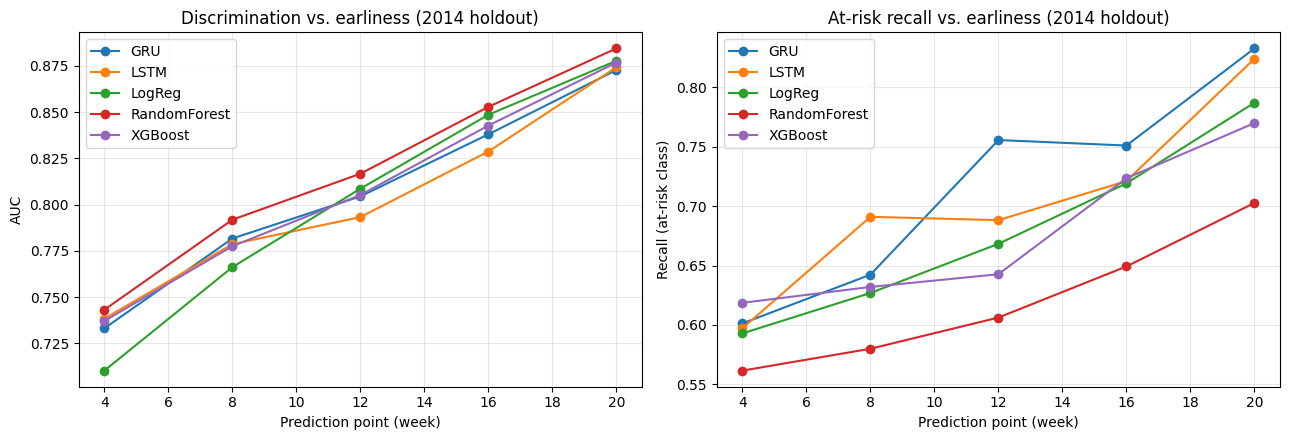

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, g in res_v2.groupby("model"):
    axes[0].plot(g.week, g.auc, marker="o", label=m)
    axes[1].plot(g.week, g.recall_at_risk, marker="o", label=m)
axes[0].set(xlabel="Prediction point (week)", ylabel="AUC",
            title="Discrimination vs. earliness (2014 holdout)")
axes[1].set(xlabel="Prediction point (week)", ylabel="Recall (at-risk class)",
            title="At-risk recall vs. earliness (2014 holdout)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("auc_vs_horizon_holdout.png", dpi=200, bbox_inches="tight")
plt.show()

## Sanity checks + what to compare

* Test at-risk rates will differ slightly from train — that's the point of the
  holdout; report both rates in your dataset table.
* Compare `res_v2` against your earlier `res`: (a) did the DL-vs-ML gap close
  once the RNNs got assessments + demographics? (b) did everyone's AUC drop a
  little on the year holdout vs. the random split? A small drop is normal and
  worth one sentence in the paper — it quantifies the optimism of random splits.
* Next upgrades, unchanged: 5 seeds per configuration, Friedman + Nemenyi,
  then the equal Optuna budget.


## 9. Interpretability: SHAP for XGBoost (week 8)

Re-trains XGBoost at the week-8 horizon and plots SHAP values — the
interpretability dimension of your comparison. For the deep models, the
analogous analysis is attention weights or integrated gradients (e.g. via
`captum`), which you can compare qualitatively in the paper.


/tmp/ipykernel_479/1966954042.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample_data, max_display=15)


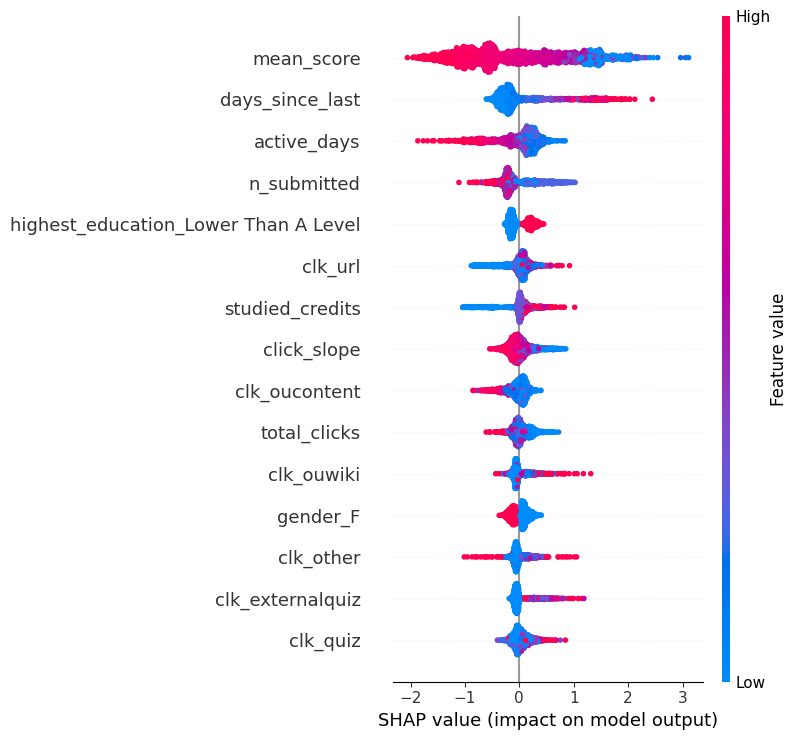

In [21]:
import re
import shap
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split

H = 8
cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= H * 7)]
cohort = cohort.reset_index(drop=True)

# 1. Generate the tabular data
Xtab, y = build_tabular(H, cohort)

# ---- FIX: Clean column names for XGBoost right after creation ----
regex = re.compile(r"\[|\]|<", re.IGNORECASE)
Xtab.columns = [
    regex.sub("_", col) if any(x in str(col) for x in ["[", "]", "<"]) else col
    for col in Xtab.columns
]
Xtab.columns = Xtab.columns.astype(str)
# ------------------------------------------------------------------

# 2. Split data
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)

# 3. Train the model
model = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          tree_method="hist", random_state=SEED)
model.fit(Xtab.iloc[tr], y[tr])

# 4. Run SHAP explanations
explainer = shap.TreeExplainer(model)
sample_data = Xtab.iloc[te].sample(2000, random_state=SEED)
sv = explainer.shap_values(sample_data)

# 5. Generate plot
shap.summary_plot(sv, sample_data, max_display=15)

## 10. Upgrades before submission

1. **Cohort holdout** — train on `code_presentation` values ending in `2013B/2013J`,
   test on `2014B/2014J`. Replaces the random split and tests generalisation to
   a new academic year.
2. **Repeated runs + significance** — 5 seeds per model per horizon, then a
   Friedman test with post-hoc Nemenyi (or pairwise Wilcoxon) across models.
   `scipy.stats` and the `scikit-posthocs` package cover both.
3. **Equal tuning budget** — replace the default hyperparameters with an
   Optuna search of ~30 trials per model, identical budget for classical and
   deep, and report the search spaces in a table.
4. **More deep baselines** — a 1D-CNN and a small transformer encoder slot
   directly into `train_rnn`'s place; both train fine on a T4.
5. **Ablations** — with/without demographics (fairness angle), and
   sequence-only vs. sequence+assessment channels.
6. **Cost table** — you're already logging `train_secs`; add per-student
   inference time and peak GPU memory (`torch.cuda.max_memory_allocated()`).
